[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leehart3000/zarrextract/blob/main/notebooks/cmip6_tas.ipynb)

# Climate model air temperature with zarrextract

This notebook reads small pieces of a CMIP6 climate model store on AWS Open Data: a monthly time series at one place and a box that crosses the prime meridian. Nothing is downloaded except the chunks that overlap each selection.

The store holds `tas`, the near-surface air temperature, from the MRI MRI-ESM2-0 model, historical experiment (1850 to 2014), member r1i1p1f1. The data are in kelvin and we show degrees Celsius. The store was chosen after checking that its time coordinate is sorted, because some CMIP6 stores in the cloud are not.

**Licence.** The data are licensed under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). The [CMIP6 Terms of Use](https://pcmdi.llnl.gov/CMIP6/TermsOfUse) say that all modelling groups relaxed their licences to CC BY 4.0 in October 2022, and that the CMIP6 licence page supersedes the `license` attribute in the files. The store's own `license` attribute is printed below. It may still show an older, more restrictive licence, and that older text no longer applies.

**Citation.** Yukimoto, S. et al. (2019). MRI MRI-ESM2.0 model output prepared for CMIP6 CMIP historical. Version 20190222. Earth System Grid Federation. https://doi.org/10.22033/ESGF/CMIP6.6842 (check the full author list at the DOI).

**Acknowledgements.** As the Terms of Use ask, we acknowledge the World Climate Research Programme, which, through its Working Group on Coupled Modelling, coordinated and promoted CMIP6. We thank the climate modelling group (MRI, Meteorological Research Institute, Japan) for producing and making available their model output, the Earth System Grid Federation (ESGF) for archiving the data and providing access, and the multiple funding agencies who support CMIP6 and ESGF.

## Install

Colab already has `fsspec`. `s3fs` needs the same version of it, so pin `s3fs` to that version and Colab's `fsspec` is not upgraded.

In [1]:
import fsspec  # noqa: F401 (used in the %pip line)

%pip install -q zarrextract "s3fs=={fsspec.__version__}"

In [2]:
import time
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import numpy as np
import zarr

import zarrextract as zx

STORE = (
    "s3://cmip6-pds/CMIP6/CMIP/MRI/MRI-ESM2-0/historical/"
    "r1i1p1f1/Amon/tas/gn/v20190222/"
)
VARIABLE = "tas"
OPTIONS = {"anon": True}  # a public bucket: no credentials
KELVIN = 273.15

accessed = datetime.now(UTC).strftime("%Y-%m-%d")
print(
    "Yukimoto, S. et al. (2019). MRI MRI-ESM2.0 model output prepared "
    "for CMIP6 CMIP historical. Version 20190222. Earth System Grid "
    f"Federation. https://doi.org/10.22033/ESGF/CMIP6.6842 (accessed {accessed})"
)

Yukimoto, S. et al. (2019). MRI MRI-ESM2.0 model output prepared for CMIP6 CMIP historical. Version 20190222. Earth System Grid Federation. https://doi.org/10.22033/ESGF/CMIP6.6842 (accessed 2026-11-26)


## The store's own licence attribute

The files carry a `license` attribute written when the data were published. Since October 2022 the CMIP6 licence page supersedes it, and the data are CC BY 4.0.

In [3]:
root = zarr.open_group(STORE, mode="r", storage_options=OPTIONS)
print(root.attrs.get("license", "(the store has no license attribute)"))

CMIP6 model data produced by MRI is licensed under a Creative Commons Attribution-ShareAlike 4.0 International License (https://creativecommons.org/licenses/). Consult https://pcmdi.llnl.gov/CMIP6/TermsOfUse for terms of use governing CMIP6 output, including citation requirements and proper acknowledgment. Further information about this data, including some limitations, can be found via the further_info_url (recorded as a global attribute in this file). The data producers and data providers make no warranty, either express or implied, including, but not limited to, warranties of merchantability and fitness for a particular purpose. All liabilities arising from the supply of the information (including any liability arising in negligence) are excluded to the fullest extent permitted by law.


## Look at the store

`describe()` lists the arrays without reading any data.

In [4]:
description = zx.describe(STORE, storage_options=OPTIONS)
for array in description:
    print(array.name, array.dimensions, array.shape, array.chunks, array.dtype)

height () () () float64
lat ('lat',) (160,) (160,) float64
lat_bnds ('lat', 'bnds') (160, 2) (160, 2) float64
lon ('lon',) (320,) (320,) float64
lon_bnds ('lon', 'bnds') (320, 2) (320, 2) float64
tas ('time', 'lat', 'lon') (1980, 160, 320) (600, 160, 320) float32
time ('time',) (1980,) (1980,) float64
time_bnds ('time', 'bnds') (1980, 2) (1980, 2) float64


`tas` has the dimensions time, lat and lon. The time coordinate says how to turn its numbers into dates through its `units` and `calendar` attributes, and the longitude runs from 0 to about 359, not from -180 to 180.

In [5]:
time_attrs = root["time"].attrs
print("calendar:", time_attrs.get("calendar"))
print("units:   ", time_attrs.get("units"))

lon_values = root["lon"][:]
print(f"lon runs from {lon_values.min():.2f} to {lon_values.max():.2f}")

calendar: proleptic_gregorian
units:    days since 1850-01-01
lon runs from 0.00 to 358.88


## A monthly time series at London

The longitude of London is -0.1, but this store uses 0 to 360. zarrextract converts -0.1 to 359.9 and picks the nearest grid column. The grid is coarse (about 1.1 degrees), and the nearest column may lie across the seam at 0, so look at the `lon` and `lat` columns to see which cell you got.

A `(start, stop)` pair picks every value from start to stop, inclusive. The result has one row per month, 1980 rows for 1850 to 2014.

In [6]:
start = time.perf_counter()
series = zx.extract(
    STORE,
    VARIABLE,
    lat=51.5,
    lon=-0.1,
    time=("1850-01-01", "2014-12-31"),
    storage_options=OPTIONS,
)
elapsed = time.perf_counter() - start

print(f"{series.num_rows} rows in {elapsed:.1f} s")
print("requested lon -0.1, store lon:", series["lon"][0].as_py())
print("requested lat 51.5, store lat:", series["lat"][0].as_py())

1980 rows in 3.3 s
requested lon -0.1, store lon: 0.0
requested lat 51.5, store lat: 51.02769


The thin line shows the monthly values, which are dominated by the seasons. The thick line is a 12-month running mean, computed with numpy, plotted at the last month of each window.

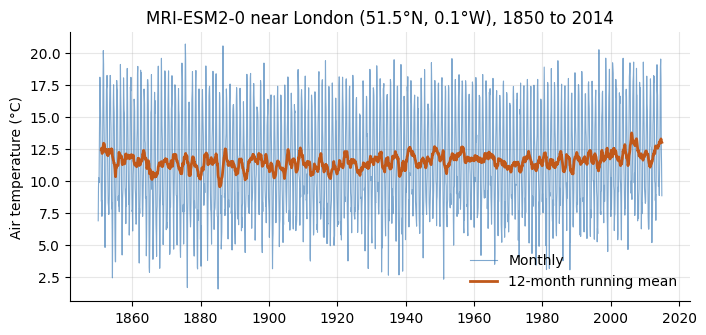

In [7]:
times = series["time"].to_numpy()
celsius = series[VARIABLE].to_numpy() - KELVIN

window = 12
running = np.convolve(celsius, np.ones(window) / window, mode="valid")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(times, celsius, color="#2a6fb0", linewidth=0.8, alpha=0.6, label="Monthly")
ax.plot(
    times[window - 1 :],
    running,
    color="#c0581a",
    linewidth=2,
    label="12-month running mean",
)
ax.set_ylabel("Air temperature (°C)")
ax.set_title("MRI-ESM2-0 near London (51.5°N, 0.1°W), 1850 to 2014")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## A box across the prime meridian

A longitude range from -11 to 2 crosses the edge of this 0 to 360 store. zarrextract reads both sides and joins them in request order, so the `lon` column runs 349... 359, then 0... 2, not in ascending order. The table is in long format, with one row per grid cell in C order (longitude changes fastest), so a reshape turns it back into a grid whose columns follow the same order.

The monthly values are stamped in the middle of the month, so the range for July 2014 holds one time step.

In [8]:
start = time.perf_counter()
box = zx.extract(
    STORE,
    VARIABLE,
    lat=(49, 61),
    lon=(-11, 2),
    time=("2014-07-01", "2014-07-31"),
    storage_options=OPTIONS,
)
elapsed = time.perf_counter() - start
print(f"{box.num_rows} rows in {elapsed:.1f} s")

lon_all = box["lon"].to_numpy()
n_lon = np.unique(lon_all).size  # longitudes per row, in request order across the seam
print("lon column starts:", np.round(lon_all[:n_lon], 2))

110 rows in 0.7 s
lon column starts: [349.88 351.   352.12 353.25 354.38 355.5  356.62 357.75 358.88   0.
   1.12]


For the image only, we turn longitudes above 180 into negative values (350 becomes -10), so the axis reads in degrees east and west and increases from left to right. The data are not changed.

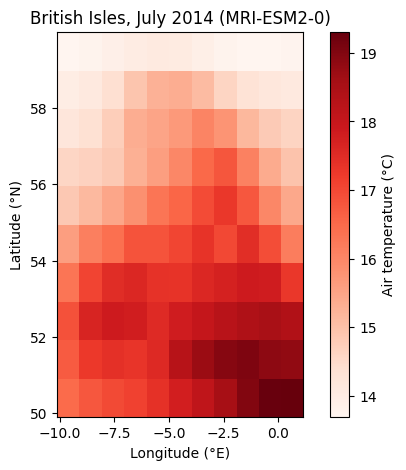

In [9]:
lat_all = box["lat"].to_numpy()
n_lat = lat_all.size // n_lon

lat = lat_all.reshape(n_lat, n_lon)[:, 0]
lon = lon_all.reshape(n_lat, n_lon)[0]
lon = np.where(lon > 180, lon - 360, lon)  # for display only
grid = box[VARIABLE].to_numpy().reshape(n_lat, n_lon) - KELVIN
if lat[0] > lat[-1]:  # draw north at the top whatever the store's order
    lat, grid = lat[::-1], grid[::-1]

fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(
    grid,
    origin="lower",
    extent=(lon[0], lon[-1], lat[0], lat[-1]),
    aspect=1 / np.cos(np.radians(55)),
    cmap="Reds",
)
fig.colorbar(image, ax=ax, label="Air temperature (°C)")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("British Isles, July 2014 (MRI-ESM2-0)")
plt.show()

## A note on calendars

Many CMIP6 models use the `noleap` or `365_day` calendar, in which every year has 365 days. zarrextract doesn't decode those calendars yet and raises `UnsupportedCalendarError` for them. This model was chosen because its time coordinate uses `proleptic_gregorian`, which zarrextract does decode.